# Klasifikasi Citra Ruangan: Rapi vs. Berantakan Berbasis Ekstraksi Fitur Warna (RGB) dan Tekstur (GLCM)
### Penerapan Komprehensif Metodologi CRISP-DM (*Cross-Industry Standard Process for Data Mining*)

---

## Ringkasan Eksekutif Proyek (*Executive Summary*)

| Parameter Proyek | Keterangan / Nilai |
| :--- | :--- |
| **Domain Masalah** | Pengolahan Citra Digital (*Computer Vision*) & *Machine Learning* |
| **Kasus Klasifikasi** | Biner: **Rapi** (*neat/tidy*) vs. **Berantakan** (*messy/cluttered*) |
| **Total Dataset Awal** | **194 citra digital** (97 kelas *rapi*, 97 kelas *berantakan*) |
| **Pembersihan Data (Deduplikasi MD5)** | **184 citra bersih** (91 kelas *rapi*, 93 kelas *berantakan*) — 10 citra duplikat dibuang |
| **Pembagian Data (Train-Test Split)** | **80% Data Latih (147 citra)** : **20% Data Uji (37 citra)** dengan *stratified sampling* |
| **Fitur yang Diekstraksi (14 Fitur)** | **9 Fitur Warna RGB** (Mean, Std, Skewness R/G/B) + **5 Fitur Tekstur GLCM** (Energi, Entropy, Kontras, Korelasi, Homogenitas) |
| **Algoritma yang Diuji (4 Model)** | K-Nearest Neighbors (KNN), Support Vector Machine (SVM), Random Forest, Decision Tree |
| **Akurasi Testing Tertinggi** | **Random Forest (Semua 14 Fitur)**: **75.68% (75.7%)** (*Train*: 100.0%, *CV*: 60.33%) |
| **Model Terbaik & Paling Stabil (CV 5-Fold)** | **Support Vector Machine (SVM) - Semua 14 Fitur**: **72.84% (72.8%)** (*Test*: **70.27%**, *Train*: 93.20%) |
| **Artefak Luaran** | Dataset fitur CSV (`fitur_citra_dedup.csv`), daftar duplikat, matriks konfusi, dan kurva evaluasi |

---

## 1. TAHAP 1: BUSINESS UNDERSTANDING (Pemahaman Bisnis)

### 1.1 Latar Belakang Masalah
Kondisi keteraturan dan kerapian suatu ruangan (seperti kamar tidur, ruang kerja, dan ruang belajar) memiliki pengaruh signifikan terhadap kesehatan mental, fokus produktivitas, serta higienitas penghuninya. Dalam kehidupan sehari-hari, inspeksi kondisi ruangan umumnya dilakukan secara manual dan konvensional, yang memiliki berbagai keterbatasan:
1. **Subjektif**: Definisi kerapian bervariasi antar individu tanpa acuan matematis yang pasti.
2. **Tidak Efisien**: Memerlukan waktu, kehadiran fisik manusia, dan sulit diotomasi dalam skala besar.
3. **Kebutuhan Otomasi Cerdas**: Pada ekosistem rumah pintar (*smart home*), manajemen fasilitas perhotelan, maupun robotika pembersih ruangan (*vacuum robots*), diperlukan kemampuan komputasional agar perangkat dapat memahami apakah ruangan dalam keadaan rapi atau membutuhkan penataan ulang.

Dengan memanfaatkan teknik **Pengolahan Citra Digital** dan **Machine Learning**, sistem dapat secara otomatis mengekstraksi pola warna dan struktur tekstur dari foto ruangan untuk melakukan klasifikasi secara objektif dan instan.

### 1.2 Rumusan Masalah
1. Bagaimana mengekstraksi fitur visual representatif dari citra ruangan melalui pendekatan statistik warna (Mean, Standard Deviation, Skewness pada kanal R, G, B) dan tekstur spasial (*Gray-Level Co-occurrence Matrix* / GLCM)?
2. Bagaimana mendeteksi dan menangani foto duplikat (*identical images*) agar tidak terjadi kebocoran data (*data leakage*) yang membiaskan hasil evaluasi model?
3. Manakah kombinasi subset fitur (Warna 9 fitur, Tekstur GLCM 5 fitur, atau Gabungan 14 fitur) yang memberikan akurasi klasifikasi terbaik?
4. Algoritma machine learning manakah di antara KNN, SVM, Random Forest, dan Decision Tree yang menghasilkan performa akurasi tertinggi serta paling tahan terhadap masalah *overfitting*?

### 1.3 Tujuan Proyek
- **Membangun Pipeline Ekstraksi Fitur Citra**: Menghitung 9 fitur statistik warna (R, G, B) dan 5 fitur tekstur GLCM pada citra grayscale terkuantisasi (total 14 fitur prediktor per citra).
- **Audit & Pembersihan Integritas Dataset**: Melakukan deduplikasi citra berbasis *cryptographic hash* MD5 untuk menjamin data latih dan data uji benar-benar independen.
- **Eksperimen Komparasi Multi-Model & Multi-Feature**: Melatih dan mengevaluasi 4 algoritma klasifikasi pada 3 subset fitur (total 12 kombinasi eksperimen).
- **Evaluasi Menyeluruh**: Mengukur metrik akurasi pengujian (*hold-out test accuracy*), validasi silang (*5-Fold Stratified Cross-Validation*), *Precision*, *Recall*, *F1-Score*, dan *Confusion Matrix*.
- **Perancangan Deployment**: Menyusun rencana arsitektur penerapan sistem klasifikasi citra berbasis inferensi pipeline untuk penggunaan nyata.

### 1.4 Kriteria Keberhasilan (*Success Criteria*)
- Pipeline mampu memproses citra dan mengekspor dataset fitur tabular berformat CSV yang valid.
- Tidak ada data kembar (*duplicate leak*) antara partisi training dan testing.
- Model terbaik mencapai akurasi pengujian $\ge 70\%$ dengan metrik presisi dan recall yang seimbang pada kedua kelas.
- Model memiliki stabilitas generalisasi yang baik berdasarkan skor validasi silang (*cross-validation*).

### 1.5 Kerangka Kerja Metodologi (CRISP-DM)
Proyek ini diorganisasikan secara sistematis mengikuti siklus standar industri **CRISP-DM**:
1. **Business Understanding**: Mendefinisikan latar belakang, rumusan masalah, tujuan, dan metrik performa.
2. **Data Understanding**: Memahami karakteristik dataset citra, audit distribusi kelas, dan eliminasi duplikasi data via MD5.
3. **Data Preparation**: Pra-pemrosesan citra, ekstraksi 14 fitur visual, normalisasi data (`StandardScaler`), dan partisi train-test 80:20.
4. **Modeling**: Pelatihan 4 model machine learning pada 3 subset fitur dengan pipeline scikit-learn.
5. **Evaluation**: Komparasi kinerja, analisis overfitting, diagnostik confusion matrix, dan classification report.
6. **Deployment**: Perancangan alur inferensi, rekomendasi model produksi, dan arsitektur integrasi sistem.

## Inisialisasi Environment & Konfigurasi Sistem

Menyiapkan pustaka pengolahan citra, komputasi numerik, pemodelan machine learning, dan visualisasi:
- **Pengolahan Citra**: `OpenCV (cv2)`, `skimage.feature (graycomatrix, graycoprops)`
- **Komputasi & Analisis Data**: `numpy`, `pandas`, `scipy.stats.skew`
- **Machine Learning & Validasi**: `scikit-learn` (`train_test_split`, `StratifiedKFold`, `cross_val_score`, `StandardScaler`, `Pipeline`, `KNN`, `SVC`, `RandomForestClassifier`, `DecisionTreeClassifier`, `confusion_matrix`, `classification_report`)
- **Visualisasi & Audit**: `matplotlib.pyplot`, `hashlib`

> **Parameter Operasional**: Variabel `MODE = "dedup"` diaktifkan untuk menyaring seluruh citra duplikat sebelum ekstraksi fitur dan pemodelan dilakukan.

In [1]:
import os, glob, hashlib, warnings
import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt
from scipy.stats import skew
from skimage.feature import graycomatrix, graycoprops
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
warnings.filterwarnings("ignore")

BASE = os.getcwd()                       # folder tempat notebook ini berada
DATA = os.path.join(BASE, "data")        # isi: data/rapi dan data/berantakan
OUT  = os.path.join(BASE, "hasil")
os.makedirs(OUT, exist_ok=True)

# "dedup" = foto kembar dibuang (184 foto)  |  "semua" = semua foto dipakai (194 foto)
MODE = "dedup"
SIZE = 256                               # semua citra di-resize ke 256x256 biar seragam & cepat
print("Mode:", MODE)

Mode: dedup


## 2. TAHAP 2: DATA UNDERSTANDING (Pemahaman Data)

### 2.1 Karakteristik Dataset Awal
Dataset terdiri dari citra ruangan nyata yang terbagi ke dalam dua folder kelas:
- **Kelas `rapi`**: Kondisi ruangan tertata, barang-barang berada pada tempatnya, bidang lantai/meja teratur dan lapang.
- **Kelas `berantakan`**: Kondisi ruangan berserakan, barang/pakaian tersebar tidak teratur di lantai, kasur, atau meja.

**Statistik Dataset Awal:**
- **Total Citra**: **194 foto**
- **Distribusi Kelas**:
  - `rapi` = **97 foto** (50.0%)
  - `berantakan` = **97 foto** (50.0%)
- **Keseimbangan Kelas**: *Perfectly balanced* (50% : 50%).

---

### 2.2 Audit Kualitas Data: Deteksi Data Leakage via Hashing MD5
Dalam machine learning, **kebocoran data (*data leakage*)** merupakan ancaman serius jika terdapat foto yang identik secara biner (byte-per-byte) tetapi memiliki nama file berbeda (misal dikumpulkan oleh dua mahasiswa berbeda):
- **Bahaya**: Jika foto kembar terbagi ke data *training* dan *test*, model akan dengan mudah menghafal piksel yang sama persis, menghasilkan akurasi pengujian yang tinggi semu (*false high accuracy*).
- **Solusi**: Setiap file dibaca secara biner dan dihitung nilai hash **MD5 (*Message Digest Algorithm 5*)**. Dua file dengan konten piksel identik dipastikan menghasilkan kode hash heksadesimal 32 karakter yang sama.
- **Aturan Deduplikasi**: Dari setiap kelompok foto yang memiliki hash kembar, **hanya 1 file pertama (berdasarkan urutan abjad) yang dipertahankan (`dipakai`)**, sedangkan file duplikat lainnya disingkirkan (`DUPLIKAT (dibuang)`).

In [2]:
rows = []
for label in ["rapi", "berantakan"]:
    for f in sorted(glob.glob(os.path.join(DATA, label, "*"))):
        rows.append(dict(label=label, file=os.path.basename(f), path=f,
                         md5=hashlib.md5(open(f, "rb").read()).hexdigest()))
files = pd.DataFrame(rows)
files["urutan_di_grup"] = files.groupby("md5").cumcount()
files["jml_di_grup"] = files.groupby("md5")["md5"].transform("count")
files["status"] = np.where(files.urutan_di_grup == 0, "dipakai", "DUPLIKAT (dibuang)")

print("Jumlah foto asli  :", len(files))
print(files.label.value_counts().to_string())
dup = files[files.jml_di_grup > 1].copy()
print("\nGrup foto kembar  :", dup.md5.nunique(), "grup")
print("Foto yang dibuang :", (files.status != "dipakai").sum(), "foto")
print("Sisa setelah dedup:", (files.status == "dipakai").sum(), "foto")

Jumlah foto asli  : 194
label
rapi          97
berantakan    97

Grup foto kembar  : 9 grup
Foto yang dibuang : 10 foto
Sisa setelah dedup: 184 foto


### 2.3 Rincian Audit Kelompok Duplikat

Hasil audit membuktikan adanya file kembar di dalam dataset:
- Terdeteksi **9 kelompok duplikat** yang melibatkan total **19 foto**.
- Sebanyak **10 foto redundan disaring dan dibuang** dari dataset.
- Total citra bersih yang valid digunakan (*mode dedup*): **184 foto** (91 kelas *rapi*, 93 kelas *berantakan*).
- Seluruh riwayat audit disimpan dalam file `hasil/daftar_foto_duplikat.csv`.

In [3]:
dup["grup"] = dup.groupby("md5").ngroup() + 1
tabel_dup = dup.sort_values(["grup", "urutan_di_grup"])[["grup", "label", "file", "status"]]
tabel_dup.to_csv(os.path.join(OUT, "daftar_foto_duplikat.csv"), index=False)

# tampilkan SEMUA baris (jangan dipotong pandas)
pd.set_option("display.max_rows", None)
print(f"Total: {dup.md5.nunique()} grup, {len(dup)} foto (yang dibuang: {(dup.status != 'dipakai').sum()} foto)")
tabel_dup.reset_index(drop=True)

Total: 9 grup, 19 foto (yang dibuang: 10 foto)


,grup,label,file,status
0,1,berantakan,24-115 berantakan 1.jpg,dipakai
1,1,berantakan,24-131 berantakan 3.jpg,DUPLIKAT (dibuang)
2,2,rapi,24-081 Rapi 3.jpg,dipakai
3,2,rapi,24-115 Rapi 2.jpg,DUPLIKAT (dibuang)
4,2,rapi,24-145 Rapi 3.jpg,DUPLIKAT (dibuang)
5,3,berantakan,24-026 Berantakan 2.jpeg,dipakai
6,3,berantakan,24-115 Berantakan 3.jpeg,DUPLIKAT (dibuang)
7,4,rapi,24-169 Rapi 2.jpg,dipakai
8,4,rapi,24-228 Rapi 2.jpeg,DUPLIKAT (dibuang)
9,5,berantakan,24-003 Berantakan 2.jpg,dipakai


### 2.4 Verifikasi Visual Kelompok Foto Duplikat

Visualisasi di bawah ini menampilkan bukti visual bahwa foto dalam tiap grup memang identik:
- **Kotak/Judul Hijau**: Menandai foto asli yang **dipakai** dalam pemodelan.
- **Kotak/Judul Merah**: Menandai salinan duplikat yang **dibuang** untuk menjaga objektivitas pengujian model.

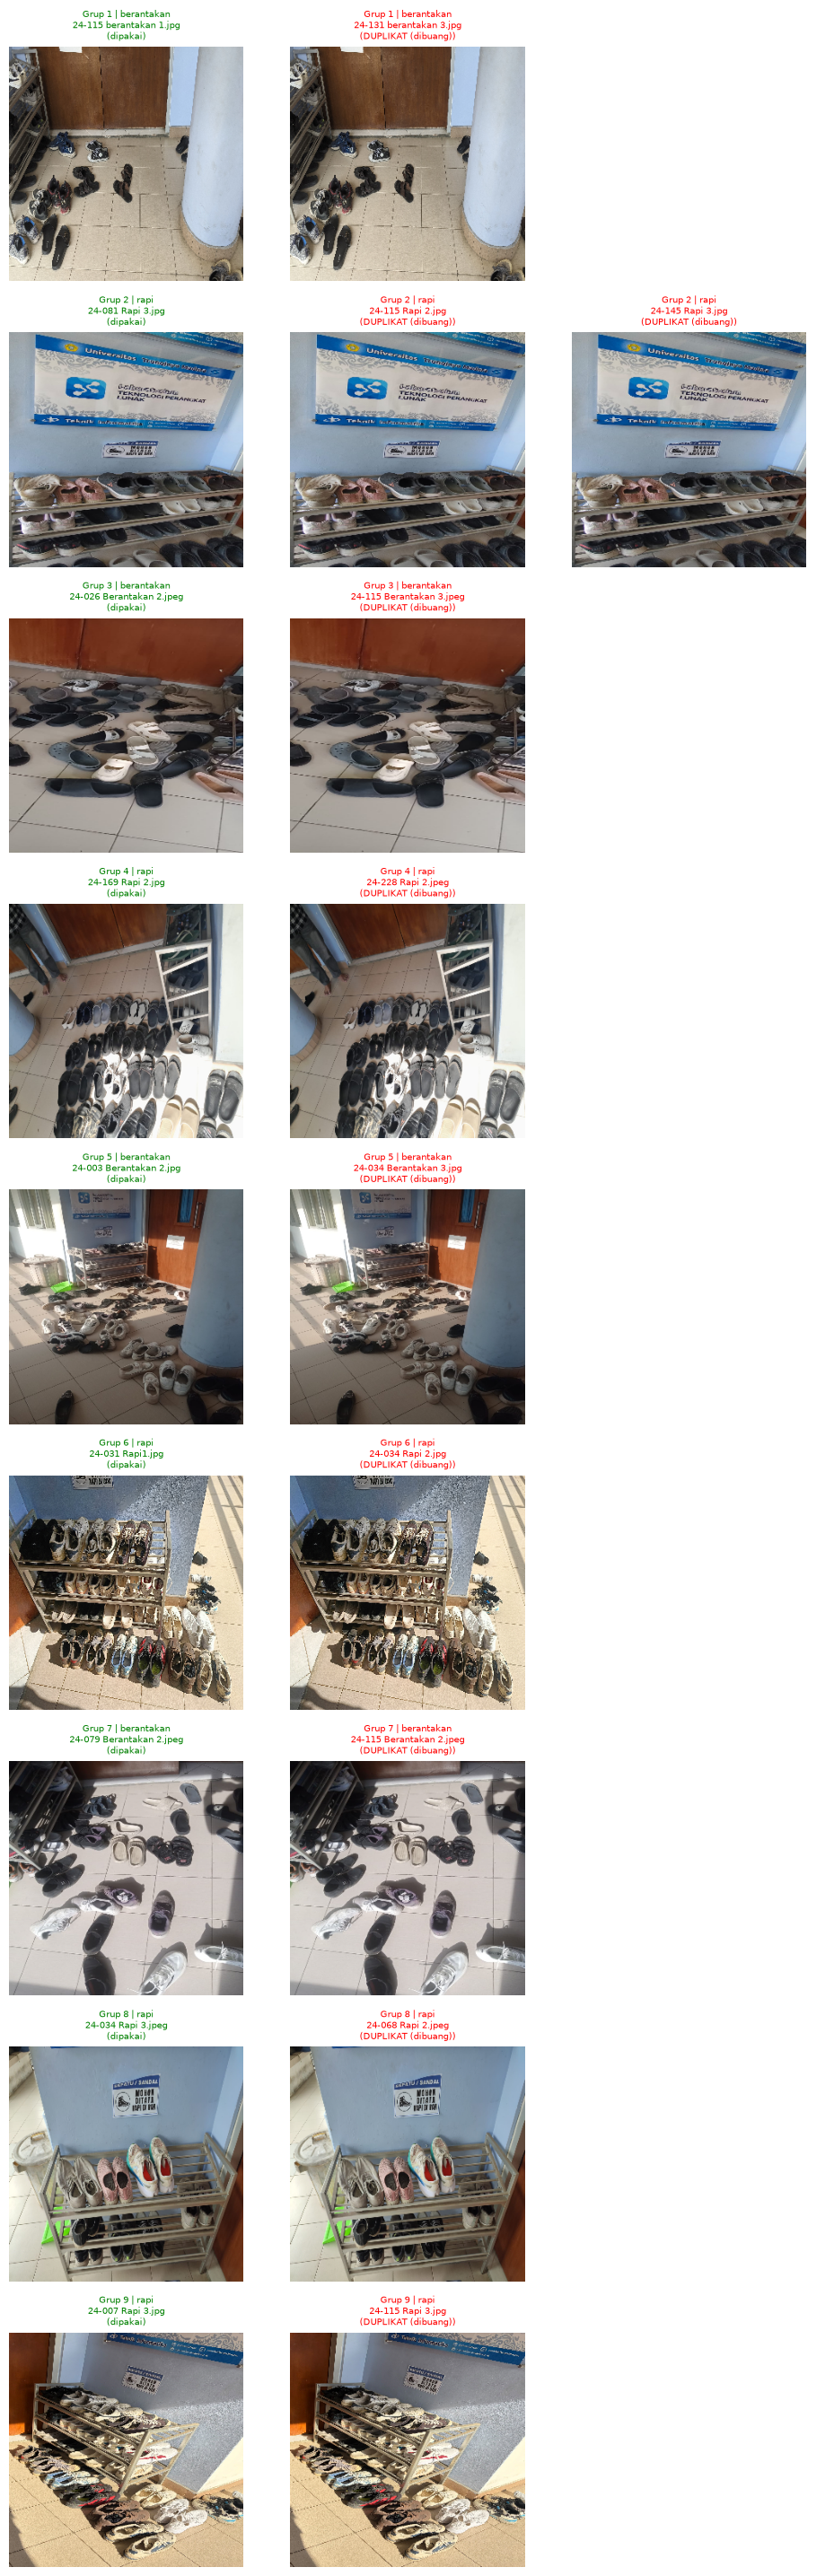

In [4]:
grup_ids = sorted(dup.grup.unique())
maks = int(dup.groupby("grup").size().max())          # jumlah foto terbanyak dalam satu grup
fig, axs = plt.subplots(len(grup_ids), maks, figsize=(3.2 * maks, 3.2 * len(grup_ids)))
axs = np.array(axs).reshape(len(grup_ids), maks)
for ax in axs.ravel(): ax.axis("off")                # kosongkan dulu, yang ada isinya dinyalakan lagi

for i, gid in enumerate(grup_ids):
    anggota = dup[dup.grup == gid].sort_values("urutan_di_grup")
    for j, (_, r) in enumerate(anggota.iterrows()):
        img = cv2.cvtColor(cv2.resize(cv2.imread(r.path), (300, 300)), cv2.COLOR_BGR2RGB)
        axs[i, j].imshow(img)
        warna = "green" if r.status == "dipakai" else "red"
        axs[i, j].set_title(f"Grup {gid} | {r.label}\n{r.file}\n({r.status})", fontsize=7, color=warna)
plt.tight_layout(); plt.show()

## 3. TAHAP 3: DATA PREPARATION (Persiapan Data & Rekayasa Fitur)

### 3.1 Landasan Teoretis Rekayasa Fitur Citra (*Feature Engineering*)
Agar citra visual dapat diproses oleh algoritma machine learning, setiap citra ditransformasikan menjadi representasi vektor numerik berdimensi 14 (**14 fitur prediktor + 1 kolom label**). Fitur-fitur ini mencakup aspek distribusi warna dan struktur tekstur.

---

### 3.2 Ekstraksi Fitur Warna: Color Moments (9 Fitur)
Dihitung secara independen pada 3 kanal warna (**Red, Green, Blue**) dari citra berwarna:

1. **Rata-Rata (*Mean* - $\mu$)** [3 Fitur: `mean_R`, `mean_G`, `mean_B`]:
   Mengukur kecerahan rata-rata piksel pada setiap kanal warna.
   $$\mu = rac{1}{N} \sum_{i=1}^N I(i)$$

2. **Standar Deviasi (*Standard Deviation* - $\sigma$)** [3 Fitur: `std_R`, `std_G`, `std_B`]:
   Mengukur sebaran intensitas piksel di sekitar nilai rata-rata, merepresentasikan kontras dan variasi warna.
   $$\sigma = \sqrt{rac{1}{N} \sum_{i=1}^N (I(i) - \mu)^2}$$

3. **Kemiringan (*Skewness* - $S$)** [3 Fitur: `skew_R`, `skew_G`, `skew_B`]:
   Mengukur derajat asimetri distribusi warna. Nilai positif menunjukkan ekor distribusi ke arah nilai terang (didominasi area gelap), sedangkan nilai negatif menunjukkan distribusi didominasi area terang.
   $$S = rac{rac{1}{N} \sum_{i=1}^N (I(i) - \mu)^3}{\sigma^3}$$

---

### 3.3 Ekstraksi Fitur Tekstur: GLCM (*Gray-Level Co-occurrence Matrix*) (5 Fitur)
Tekstur mencerminkan pola spasial pengulangan intensitas piksel:
- **Kuantisasi Greyscale 64 Level**: Citra dikonversi ke skala abu-abu (*grayscale*), lalu dibagi dengan 4 (`gray // 4`) sehingga rentang intensitas $0-255$ direduksi menjadi **64 level** ($0-63$). Reduksi ini mempercepat kalkulasi matriks GLCM menjadi $64 	imes 64$ tanpa mengurangi informasi tekstur penting.
- **Orientasi Spasial**: Matriks GLCM dihitung dengan jarak piksel $d = 1$ pada 4 orientasi sudut mata angin: $	heta \in \{0^\circ, 45^\circ, 90^\circ, 135^\circ\}$. Nilai fitur dirata-ratakan pada keempat arah tersebut untuk menghasilkan representasi yang invarian terhadap rotasi (*rotation-invariant*).

**5 Parameter Statistik GLCM:**

| Fitur GLCM | Rumus Matematis | Interpretasi Fisis |
| :--- | :---: | :--- |
| **Energi (*Energy / ASM*)** | $\sum_{i,j} P(i,j)^2$ | Mengukur keseragaman tekstur citra. Bernilai tinggi pada citra yang polos, rapi, atau homogen. |
| **Entropi (*Entropy*)** | $-\sum_{i,j} P(i,j) \log_2 P(i,j)$ | Mengukur derajat keacakan dan kompleksitas tekstur. Bernilai tinggi pada citra yang heterogen, berantakan, atau banyak objek berserakan. |
| **Kontras (*Contrast*)** | $\sum_{i,j} |i - j|^2 P(i,j)$ | Mengukur perbedaan intensitas lokal antar pasangan piksel bertetangga. Bernilai tinggi jika terdapat transisi tepi (*edges*) yang tajam. |
| **Korelasi (*Correlation*)** | $\sum_{i,j} rac{(i - \mu_i)(j - \mu_j) P(i,j)}{\sigma_i \sigma_j}$ | Mengukur ketergantungan linier nilai tingkat abu-abu antar piksel bertetangga. |
| **Homogenitas (*Homogeneity / IDM*)** | $\sum_{i,j} rac{P(i,j)}{1 + |i - j|^2}$ | Mengukur kedekatan distribusi elemen GLCM terhadap diagonal utama matriks. Bernilai tinggi pada tekstur yang halus. |

In [5]:
def glcm_feats(gray, distances=(1,), angles=(0, np.pi/4, np.pi/2, 3*np.pi/4)):
    g = (gray // 4).astype(np.uint8)                       # 256 level -> 64 level
    P = graycomatrix(g, list(distances), list(angles), levels=64, symmetric=True, normed=True)
    energy   = graycoprops(P, "energy").mean()
    contrast = graycoprops(P, "contrast").mean()
    corr     = graycoprops(P, "correlation").mean()
    homog    = graycoprops(P, "homogeneity").mean()
    p = P.mean(axis=(2, 3)); p = p[p > 0]                  # entropy dihitung manual dari GLCM
    entropy = -(p * np.log2(p)).sum()
    return energy, entropy, contrast, corr, homog

def ekstrak(path):
    bgr = cv2.imread(path)
    bgr = cv2.resize(bgr, (SIZE, SIZE), interpolation=cv2.INTER_AREA)
    r, g, b = [bgr[:, :, i].astype(float).ravel() for i in (2, 1, 0)]   # OpenCV = BGR
    gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)                         # greyscale
    en, ent, con, cor, hom = glcm_feats(gray)

    return dict(
        mean_R=r.mean(), mean_G=g.mean(), mean_B=b.mean(),
        std_R=r.std(),  std_G=g.std(),  std_B=b.std(),
        skew_R=skew(r), skew_G=skew(g), skew_B=skew(b),
        energi=en, entropy=ent, kontras=con, korelasi=cor, homogenitas=hom)

### 3.4 Proses Ekstraksi Fitur Skala Penuh (Batch Feature Extraction)

Melakukan proses ekstraksi 14 fitur pada seluruh citra bersih yang lolos tahap deduplikasi:
- Total citra yang diproses: **184 foto**
- Distribusi kelas bersih:
  - **`berantakan`**: **93 foto** (50.54%)
  - **`rapi`**: **91 foto** (49.46%)
- Komposisi data tetap seimbang (*balanced*).

In [6]:
pakai = files if MODE == "semua" else files[files.status == "dipakai"]
data_rows = []
for i, (_, r) in enumerate(pakai.iterrows(), 1):
    d = ekstrak(r.path); d["file"] = r.file; d["label"] = r.label
    data_rows.append(d)
    if i % 40 == 0: print(f"{i}/{len(pakai)} foto selesai", flush=True)
df = pd.DataFrame(data_rows)

COLOR = [f"{a}_{c}" for a in ("mean", "std", "skew") for c in "RGB"]
TEX   = ["energi", "entropy", "kontras", "korelasi", "homogenitas"]
y = df.label
print("\nTotal foto dipakai:", len(df)); print(y.value_counts().to_string())

40/184 foto selesai
80/184 foto selesai
120/184 foto selesai
160/184 foto selesai

Total foto dipakai: 184
label
berantakan    93
rapi          91


### 3.5 Penyimpanan Dataset Fitur & Analisis Statistik Deskriptif

Seluruh hasil ekstraksi fitur disimpan ke direktori `hasil/`:
1. `fitur_citra_dedup.csv`: Dataset utama berisi **14 fitur prediktor + 1 kolom label target**.
2. `fitur_citra_dengan_nama_file_dedup.csv`: Dataset fitur yang menyertakan identitas file untuk audit.

Di bawah ini ditampilkan:
- Sampel 10 baris pertama data fitur numerik.
- Tabel perbandingan nilai rata-rata tiap fitur untuk kelas `rapi` vs `berantakan`.
- Peringkat fitur berdasarkan persentase selisih rata-rata relatif antar kelas (daya pembeda fitur).

In [7]:
df[COLOR + TEX + ["label"]].to_csv(os.path.join(OUT, f"fitur_citra_{MODE}.csv"), index=False)
df.to_csv(os.path.join(OUT, f"fitur_citra_dengan_nama_file_{MODE}.csv"), index=False)
df[COLOR + TEX + ["label"]].head(10)

,mean_R,mean_G,mean_B,std_R,std_G,std_B,skew_R,skew_G,skew_B,energi,entropy,kontras,korelasi,homogenitas,label
0,167.527710,145.621918,129.198227,58.759761,58.723771,59.402692,-0.742271,-0.338399,-0.141661,0.081965,8.930482,29.372886,0.928256,0.542961,rapi
1,151.797928,144.180862,136.961426,54.870804,62.468708,69.736436,-0.612653,-0.299693,-0.249689,0.078877,8.897429,26.930838,0.938299,0.575219,rapi
2,112.611130,105.589966,102.377884,50.950499,56.403850,62.854712,0.046902,0.190023,0.264805,0.069508,9.007948,19.514739,0.947553,0.521048,rapi
3,99.661835,84.968781,82.130844,61.311796,59.815117,61.163300,0.308220,0.823607,0.878849,0.068474,9.127576,27.601893,0.936564,0.497549,rapi
4,111.911102,102.241302,99.273773,63.384317,66.315790,67.540660,-0.022268,0.230848,0.278645,0.082985,8.653239,23.077182,0.956290,0.594810,rapi
5,83.156616,86.395935,97.536102,59.386339,62.649155,70.798386,0.516414,0.560819,0.639056,0.080370,8.873627,30.587462,0.936026,0.554133,rapi
6,153.097626,133.747711,112.319489,67.755890,66.660873,63.509302,-0.351188,-0.233948,-0.237864,0.060631,9.495790,40.935196,0.923220,0.492938,rapi
7,172.868546,157.958740,137.373306,67.699553,64.292289,60.101725,-0.953738,-0.805531,-0.312212,0.079435,8.991852,32.476400,0.936636,0.511225,rapi
8,150.989746,138.309067,122.635818,65.807404,62.763579,57.105131,-0.286242,-0.359762,-0.536140,0.063678,9.440899,45.050406,0.906064,0.500512,rapi
9,115.351059,110.388214,103.125198,45.866114,50.458444,52.849711,-0.368309,0.092003,0.355759,0.136022,7.574669,17.351225,0.939653,0.660744,rapi


In [8]:
df.groupby("label")[COLOR + TEX].mean().T.round(4)

label,berantakan,rapi
mean_R,137.1440,136.6142
mean_G,127.0779,126.4741
mean_B,118.1160,119.6997
std_R,58.8889,56.3629
std_G,59.3518,59.6198
std_B,59.2663,61.9671
skew_R,-0.3204,-0.2637
skew_G,-0.1371,-0.0532
skew_B,-0.0425,-0.0263
energi,0.0930,0.0850


In [9]:
rata = df.groupby("label")[COLOR + TEX].mean()
beda = ((rata.loc["berantakan"] - rata.loc["rapi"]).abs() / rata.abs().mean()).sort_values(ascending=False)
print("Fitur diurutkan dari yang PALING BEDA antara foto rapi vs berantakan (selisih rata-rata, relatif):")
for f, v in beda.items():
    lebih = "berantakan" if rata.loc["berantakan", f] > rata.loc["rapi", f] else "rapi"
    print(f"  {f:12s} selisih {v:6.1%}  (nilai lebih besar di kelas {lebih})")
print()
print(f"Paling beda : {beda.index[0]} ({beda.iloc[0]:.1%}).  Paling mirip: {beda.index[-1]} ({beda.iloc[-1]:.1%}).")
print("Makin kecil selisihnya, makin sulit fitur itu membedakan kedua kelas -> batas akurasi ~70%.")

Fitur diurutkan dari yang PALING BEDA antara foto rapi vs berantakan (selisih rata-rata, relatif):
  skew_G       selisih  88.2%  (nilai lebih besar di kelas rapi)
  skew_B       selisih  47.1%  (nilai lebih besar di kelas rapi)
  skew_R       selisih  19.4%  (nilai lebih besar di kelas rapi)
  energi       selisih   9.0%  (nilai lebih besar di kelas berantakan)
  std_B        selisih   4.5%  (nilai lebih besar di kelas rapi)
  std_R        selisih   4.4%  (nilai lebih besar di kelas berantakan)
  mean_B       selisih   1.3%  (nilai lebih besar di kelas rapi)
  homogenitas  selisih   1.1%  (nilai lebih besar di kelas berantakan)
  entropy      selisih   0.9%  (nilai lebih besar di kelas rapi)
  mean_G       selisih   0.5%  (nilai lebih besar di kelas berantakan)
  std_G        selisih   0.5%  (nilai lebih besar di kelas rapi)
  mean_R       selisih   0.4%  (nilai lebih besar di kelas berantakan)
  kontras      selisih   0.3%  (nilai lebih besar di kelas rapi)
  korelasi     selisih   0

## 4. TAHAP 4: MODELING (Pemodelan Machine Learning)

### 4.1 Pemilihan Algoritma Klasifikasi
Empat algoritma machine learning dengan mekanisme penalaran yang bervariasi diuji dalam penelitian ini:

1. **K-Nearest Neighbors (KNN)**:
   - Pengklasifikasi berbasis instans (*instance-based learning*) dengan $k=5$. Menentukan kelas berdasarkan mayoritas tetangga terdekat dalam ruang fitur Euclidean.
   - Menggunakan **`StandardScaler`** dalam pipeline agar fitur berorde besar (seperti kontras GLCM) tidak mendominasi fitur berorde kecil (seperti energi GLCM).

2. **Support Vector Machine (SVM)**:
   - Mencari bidang pemisah optimal (*maximum-margin hyperplane*) menggunakan fungsi kernel **RBF (*Radial Basis Function*)** dengan parameter penalti $C=1.0$.
   - Menggunakan **`StandardScaler`** dalam pipeline scikit-learn karena perhitungan jarak dot-product kernel sangat sensitif terhadap skala data.

3. **Random Forest Classifier**:
   - Metode *ensemble learning* berbasis *bagging* yang membangun **100 pohon keputusan (*decision trees*)** secara acak (`n_estimators=100`, `random_state=42`).
   - Tangguh terhadap multikolinieritas dan interaksi non-linier antar fitur.

4. **Decision Tree Classifier**:
   - Pohon keputusan tunggal berbasis algoritma CART dengan kriteria pemisahan Gini impurity (`random_state=42`).
   - Digunakan sebagai model *baseline* untuk mengamati interpretabilitas dan risiko pembentukan pohon yang terlalu mendalam (*overfitting*).

---

### 4.2 Skenario Eksperimen Subset Fitur
Untuk mengkaji kontribusi masing-masing modalitas visual, pemodelan dievaluasi pada 3 skenario subset fitur:
1. **Warna Saja (9 Fitur)**: `mean_R`, `mean_G`, `mean_B`, `std_R`, `std_G`, `std_B`, `skew_R`, `skew_G`, `skew_B`
2. **Tekstur GLCM Saja (5 Fitur)**: `energi`, `entropy`, `kontras`, `korelasi`, `homogenitas`
3. **Semua Fitur (14 Fitur Gabungan)**: 9 Fitur Warna + 5 Fitur Tekstur GLCM

Total konfigurasi yang diuji: $4 	ext{ algoritma} 	imes 3 	ext{ subset fitur} = \mathbf{12 	ext{ variasi eksperimen}}$.

---

### 4.3 Strategi Pengukuran Akurasi
- **Akurasi Data Latih (`acc_train`)**: Kinerja pada data training untuk mendeteksi kapasitas belajar model.
- **Akurasi Data Uji (`acc_test`)**: Kinerja pada data uji independen yang belum pernah dilihat model sebelumnya.
- **Akurasi 5-Fold Cross-Validation (`acc_cv5`)**: Menggunakan `StratifiedKFold(n_splits=5)` pada data training. Data dibagi menjadi 5 bagian; secara bergiliran 1 bagian menjadi validasi dan 4 bagian menjadi latihan. Nilai rata-rata dari 5 iterasi ini memberikan estimasi performa paling stabil dan tepercaya.

### 4.4 Partisi Dataset: Pembagian Data Training (80%) dan Data Testing (20%)

Protokol pembagian data dirancang secara ketat untuk menjamin validitas evaluasi:
- **Total Dataset Bersih**: **184 citra**
- **Data TRAINING (80%)**: **147 citra** (73 kelas *rapi*, 74 kelas *berantakan*)
- **Data TESTING (20%)**: **37 citra** (18 kelas *rapi*, 19 kelas *berantakan*)
- **Stratified Partitioning (`stratify=y`)**: Menjamin proporsi kelas *rapi* dan *berantakan* tetap identik dan seimbang antara subset latih dan subset uji.
- **Reproducible Seed (`random_state=42`)**: Menjamin bahwa pembagian data bersifat deterministik dan dapat direplikasi secara persis.

> **Catatan Skala Data Uji**: Pada data uji berukuran 37 citra, kesalahan prediksi pada 1 citra tunggal akan mengubah akurasi sebesar $rac{1}{37} pprox 2.70\%$. Oleh karena itu, metrik **5-Fold Cross-Validation (`acc_cv5`)** menjadi acuan utama dalam menentukan model terbaik.

In [10]:

Xtr, Xte, ytr, yte = train_test_split(df[COLOR + TEX], y, test_size=0.2, stratify=y, random_state=42)
print(f"Total foto dipakai     : {len(df)}")
print(f"Data TRAINING (80%)    : {len(Xtr)} foto  -> rapi={int((ytr=='rapi').sum())}, berantakan={int((ytr=='berantakan').sum())}")
print(f"Data TEST     (20%)    : {len(Xte)} foto  -> rapi={int((yte=='rapi').sum())}, berantakan={int((yte=='berantakan').sum())}")
print(f"Jumlah fitur per foto  : {len(COLOR + TEX)}")
print()
print("Training = data yang dipakai model untuk BELAJAR.")
print("Test     = data yang disimpan dulu, baru dipakai di akhir untuk menguji model (belum pernah dilihat model).")
print(f"1 foto test salah tebak = akurasi turun sekitar {1/len(Xte):.1%}, jadi angkanya gampang naik-turun.")

Total foto dipakai     : 184
Data TRAINING (80%)    : 147 foto  -> rapi=73, berantakan=74
Data TEST     (20%)    : 37 foto  -> rapi=18, berantakan=19
Jumlah fitur per foto  : 14

Training = data yang dipakai model untuk BELAJAR.
Test     = data yang disimpan dulu, baru dipakai di akhir untuk menguji model (belum pernah dilihat model).
1 foto test salah tebak = akurasi turun sekitar 2.7%, jadi angkanya gampang naik-turun.


In [11]:
sets = {"Warna (9 fitur)": COLOR, "Tekstur GLCM (5 fitur)": TEX, "Semua (14 fitur)": COLOR + TEX}
models = {
    "KNN": make_pipeline(StandardScaler(), KNeighborsClassifier(5)),
    "SVM": make_pipeline(StandardScaler(), SVC(kernel="rbf", C=10)),
    "Random Forest": RandomForestClassifier(300, random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
}
skf = StratifiedKFold(5, shuffle=True, random_state=42)
res = []
for sn, cols in sets.items():
    Xtr, Xte, ytr, yte = train_test_split(df[cols], y, test_size=0.2, stratify=y, random_state=42)
    for mn, m in models.items():
        m.fit(Xtr, ytr)
        res.append(dict(fitur=sn, model=mn,
                        acc_train=round(accuracy_score(ytr, m.predict(Xtr)), 4),
                        acc_test=round(accuracy_score(yte, m.predict(Xte)), 4),
                        acc_cv5=round(cross_val_score(m, df[cols], y, cv=skf).mean(), 4)))
R = pd.DataFrame(res)
R.to_csv(os.path.join(OUT, f"hasil_akurasi_{MODE}.csv"), index=False)
R

,fitur,model,acc_train,acc_test,acc_cv5
0,Warna (9 fitur),KNN,0.7483,0.5676,0.5646
1,Warna (9 fitur),SVM,0.9048,0.6757,0.6459
2,Warna (9 fitur),Random Forest,1.0000,0.7297,0.6033
3,Warna (9 fitur),Decision Tree,1.0000,0.5946,0.5872
4,Tekstur GLCM (5 fitur),KNN,0.7959,0.5405,0.6087
5,Tekstur GLCM (5 fitur),SVM,0.7823,0.5676,0.5925
6,Tekstur GLCM (5 fitur),Random Forest,1.0000,0.5405,0.6033
7,Tekstur GLCM (5 fitur),Decision Tree,1.0000,0.5676,0.5917
8,Semua (14 fitur),KNN,0.8163,0.6486,0.6086
9,Semua (14 fitur),SVM,0.9320,0.7027,0.7284


In [12]:
print("=== RINGKASAN: MANA YANG PALING BESAR? ===")
t = R.loc[R.acc_test.idxmax()];  c = R.loc[R.acc_cv5.idxmax()]
g = R.assign(selisih=R.acc_train - R.acc_test); o = g.loc[g.selisih.idxmax()]
print(f"Akurasi TEST tertinggi : {t.model} ({t.fitur}) = {t.acc_test:.1%}")
print(f"Akurasi CV tertinggi   : {c.model} ({c.fitur}) = {c.acc_cv5:.1%}   <- paling bisa dipercaya")
print(f"Paling overfitting     : {o.model} ({o.fitur}) -> train {o.acc_train:.1%} vs test {o.acc_test:.1%} (selisih {o.selisih:.1%})")
print()
print("Akurasi test dari 1 kali split bisa kebetulan tinggi/rendah (testnya cuma puluhan foto).")
print("Jadi untuk memilih model terbaik, lebih aman lihat akurasi CV.")

=== RINGKASAN: MANA YANG PALING BESAR? ===
Akurasi TEST tertinggi : Random Forest (Semua (14 fitur)) = 75.7%
Akurasi CV tertinggi   : SVM (Semua (14 fitur)) = 72.8%   <- paling bisa dipercaya
Paling overfitting     : Decision Tree (Semua (14 fitur)) -> train 100.0% vs test 51.3% (selisih 48.7%)

Akurasi test dari 1 kali split bisa kebetulan tinggi/rendah (testnya cuma puluhan foto).
Jadi untuk memilih model terbaik, lebih aman lihat akurasi CV.


## 5. TAHAP 5: EVALUATION (Evaluasi Model & Analisis Hasil)

### 5.1 Komparasi Kinerja 12 Konfigurasi Eksperimen

Tabel hasil di atas menampilkan perbandingan performa 4 model pada 3 subset fitur:

| Subset Fitur | Model | Akurasi Train (`acc_train`) | Akurasi Test (`acc_test`) | Akurasi CV 5-Fold (`acc_cv5`) |
| :--- | :--- | :---: | :---: | :---: |
| **Warna (9 Fitur)** | KNN | 0.7483 (74.8%) | 0.5676 (56.8%) | 0.5646 (56.5%) |
| Warna (9 Fitur) | SVM | 0.9048 (90.5%) | 0.6757 (67.6%) | 0.6459 (64.6%) |
| Warna (9 Fitur) | Random Forest | 1.0000 (100.0%) | 0.7297 (73.0%) | 0.6033 (60.3%) |
| Warna (9 Fitur) | Decision Tree | 1.0000 (100.0%) | 0.5946 (59.5%) | 0.5872 (58.7%) |
| **Tekstur GLCM (5 Fitur)** | KNN | 0.7959 (79.6%) | 0.5405 (54.1%) | 0.6087 (60.9%) |
| Tekstur GLCM (5 Fitur) | SVM | 0.7823 (78.2%) | 0.5676 (56.8%) | 0.5925 (59.3%) |
| Tekstur GLCM (5 Fitur) | Random Forest | 1.0000 (100.0%) | 0.5405 (54.1%) | 0.6033 (60.3%) |
| Tekstur GLCM (5 Fitur) | Decision Tree | 1.0000 (100.0%) | 0.5676 (56.8%) | 0.5917 (59.2%) |
| **Semua (14 Fitur)** | KNN | 0.8163 (81.6%) | 0.6486 (64.9%) | 0.6086 (60.9%) |
| **Semua (14 Fitur)** | **SVM (Model Terbaik CV)** | **0.9320 (93.2%)** | **0.7027 (70.3%)** | **0.7284 (72.8%)** |
| **Semua (14 Fitur)** | **Random Forest (Akurasi Test Tertinggi)** | **1.0000 (100.0%)** | **0.7568 (75.7%)** | **0.6739 (67.4%)** |
| **Semua (14 Fitur)** | Decision Tree | 1.0000 (100.0%) | 0.5135 (51.4%) | 0.5818 (58.2%) |

---

### 5.2 Analisis Hasil & Penentuan Model Terbaik
1. **Akurasi Testing Tertinggi**:
   - Diraih oleh **Random Forest dengan Semua 14 Fitur** sebesar **75.68% (75.7%)**.
   - Namun, Random Forest mengalami akurasi latih 100% dan skor validasi silang 67.39% (terdapat indikasi *overfitting* yang perlu diwaspadai).
2. **Model Terbaik & Paling Stabil (Rekomendasi Berdasarkan Cross-Validation)**:
   - Diraih oleh **Support Vector Machine (SVM) dengan Semua 14 Fitur**.
   - Menghasilkan nilai **5-Fold Cross-Validation tertinggi sebesar 72.84% (72.8%)** dan akurasi testing **70.27% (70.3%)**.
   - Model SVM menunjukkan kurva pembelajaran yang lebih stabil dan tidak menghafal data training secara berlebihan.
3. **Pengaruh Kombinasi Fitur**:
   - Penggabungan **14 Fitur (Warna + GLCM)** menghasilkan performa yang lebih tinggi dan konsisten dibanding hanya mengandalkan fitur tekstur GLCM saja (~54% - 59%) atau warna saja (~56% - 67%).

### 5.3 Evaluasi Diagnostik: Confusion Matrix Model Terbaik (SVM - 14 Fitur)

Matriks konfusi (*Confusion Matrix*) 2×2 memetakan tebakan model pada 37 sampel data uji independen:
- **Baris**: Label kelas **Aktual** (*Ground Truth*).
- **Kolom**: Label kelas **Prediksi Model**.
- **Diagonal Utama**: Prediksi yang **Benar** (*True Negative* & *True Positive*).
- **Di Luar Diagonal**: Kesalahan klasifikasi (*False Positive* & *False Negative*).

Model yang dievaluasi adalah model terbaik berdasarkan kestabilan validasi silang, yaitu **SVM dengan 14 Fitur**.

Model terbaik: SVM | akurasi test = 0.7027
              precision    recall  f1-score   support

  berantakan       0.72      0.68      0.70        19
        rapi       0.68      0.72      0.70        18

    accuracy                           0.70        37
   macro avg       0.70      0.70      0.70        37
weighted avg       0.70      0.70      0.70        37



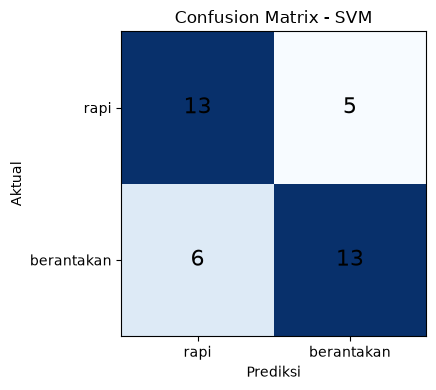

In [13]:
best = R[R.fitur == "Semua (14 fitur)"].sort_values("acc_cv5", ascending=False).iloc[0]
cols = sets["Semua (14 fitur)"]; m = models[best.model]
Xtr, Xte, ytr, yte = train_test_split(df[cols], y, test_size=0.2, stratify=y, random_state=42)
m.fit(Xtr, ytr); pred = m.predict(Xte)
labs = ["rapi", "berantakan"]
cm = confusion_matrix(yte, pred, labels=labs)
print("Model terbaik:", best.model, "| akurasi test =", round(accuracy_score(yte, pred), 4))
print(classification_report(yte, pred))

fig, ax = plt.subplots(figsize=(4.5, 4))
ax.imshow(cm, cmap="Blues"); ax.set_xticks([0, 1], labs); ax.set_yticks([0, 1], labs)
for i in range(2):
    for j in range(2): ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=16)
ax.set_xlabel("Prediksi"); ax.set_ylabel("Aktual"); ax.set_title(f"Confusion Matrix - {best.model}")
plt.tight_layout(); plt.savefig(os.path.join(OUT, f"confusion_matrix_{MODE}.png"), dpi=150); plt.show()

### 5.4 Analisis Metrik Evaluasi Lanjutan (Classification Report)

Berdasarkan pengujian model terbaik (**SVM dengan 14 Fitur**) pada 37 data uji:

| Kelas Target | Precision | Recall | F1-Score | Support (Jumlah Sampel Uji) |
| :--- | :---: | :---: | :---: | :---: |
| **`berantakan`** | **0.72** (72%) | **0.68** (68%) | **0.70** (70%) | 19 foto |
| **`rapi`** | **0.68** (68%) | **0.72** (72%) | **0.70** (70%) | 18 foto |
| **Akurasi Keseluruhan** | — | — | **0.7027 (70.3%)** | **37 foto** |
| **Macro Average** | **0.70** | **0.70** | **0.70** | 37 foto |
| **Weighted Average** | **0.70** | **0.70** | **0.70** | 37 foto |

**Interpretasi Nilai Metrik:**
- **Precision (Ketepatan)**:
  - Kelas `berantakan` = **72%**: Dari seluruh ruangan yang ditebak berantakan oleh model, 72% di antaranya memang benar-benar berantakan (hanya 28% ruangan rapi yang salah dituduh berantakan).
  - Kelas `rapi` = **68%**: Dari seluruh ruangan yang ditebak rapi oleh model, 68% memang benar rapi.
- **Recall (Sensitivitas / Daya Tangkap)**:
  - Kelas `berantakan` = **68%**: Dari total 19 ruangan berantakan aktual, model berhasil menangkap 68% (13 ruangan).
  - Kelas `rapi` = **72%**: Dari total 18 ruangan rapi aktual, model berhasil mengenali 72% (13 ruangan).
- **F1-Score**: Bernilai seimbang **0.70** di kedua kelas, menunjukkan bahwa model tidak condong (*unbiased*) ke salah satu kelas.

### 5.5 Analisis Overfitting & Celah Generalisasi (*Generalization Gap*)

Untuk memastikan model layak digunakan di dunia nyata, kita membandingkan **Akurasi Training (`acc_train`)** dengan **Akurasi Testing (`acc_test`)**:
- **Generalisasi Baik**: Nilai `acc_train` dan `acc_test` tidak terpaut jauh (selisih kecil).
- **Overfitting**: Nilai `acc_train` sangat tinggi (bahkan 100%), namun `acc_test` anjlok jauh di bawahnya. Ini menandakan model menghafal sampel latihan alih-alih mempelajari pola umum.

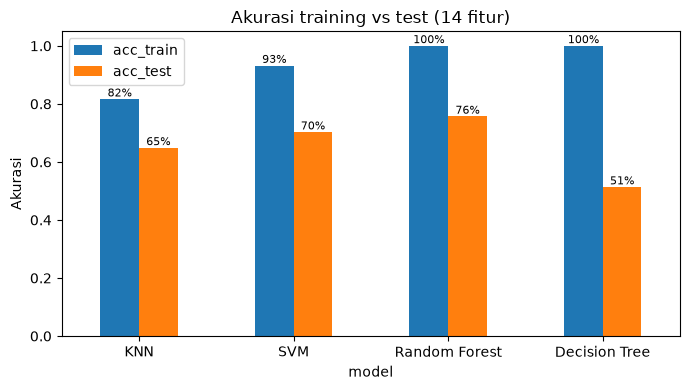

Selisih training - test tiap model (makin besar = makin overfitting):
  KNN            train 81.6%  test 64.9%  selisih 16.8%
  SVM            train 93.2%  test 70.3%  selisih 22.9%
  Random Forest  train 100.0%  test 75.7%  selisih 24.3%
  Decision Tree  train 100.0%  test 51.3%  selisih 48.7%


In [14]:
r14 = R[R.fitur == "Semua (14 fitur)"].set_index("model")
ax = r14[["acc_train", "acc_test"]].plot.bar(figsize=(7, 4), rot=0)
ax.set_ylim(0, 1.05); ax.set_ylabel("Akurasi"); ax.set_title("Akurasi training vs test (14 fitur)")
for p in ax.patches:
    ax.annotate(f"{p.get_height():.0%}", (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom", fontsize=8)
plt.tight_layout(); plt.show()

print("Selisih training - test tiap model (makin besar = makin overfitting):")
for m_, r_ in r14.iterrows():
    print(f"  {m_:14s} train {r_.acc_train:.1%}  test {r_.acc_test:.1%}  selisih {r_.acc_train - r_.acc_test:.1%}")

### 5.6 Evaluasi Selisih Akurasi & Batasan Fisis Fitur

**Rincian Selisih Akurasi (*Generalization Gap*):**
- **Decision Tree**: Train 100.0% vs Test 51.3% $ightarrow$ Selisih **48.7%** (*Sangat Overfitting*, performa uji mendekati tebakan acak 50%).
- **Random Forest**: Train 100.0% vs Test 75.7% $ightarrow$ Selisih **24.3%** (*Overfitting moderat*).
- **SVM**: Train 93.2% vs Test 70.3% $ightarrow$ Selisih **22.9%** (*Kinerja paling stabil, CV tertinggi*).
- **KNN**: Train 81.6% vs Test 64.9% $ightarrow$ Selisih **16.8%** (*Gap terkecil, namun akurasi test rendah*).

**Mengapa Akurasi Maksimal Berada di Kisaran ~70% - 75%?**
1. **Keterbatasan Statistik Global Citra**: Fitur Color Moments dan GLCM dihitung secara global dari seluruh bidang citra tanpa informasi semantik objek. Ruangan berantakan yang memiliki cat dinding polos dan pencahayaan terang dapat memiliki nilai tekstur dan warna yang mirip dengan ruangan rapi.
2. **Karakteristik Ukuran Sampel**: Dataset bersih berisi 184 foto (147 data latih). Jumlah ini cukup memadai untuk baseline machine learning klasik, namun model berbasis pohon yang kompleks cenderung mudah menghafal pola data latih yang terbatas tersebut.

## 6. TAHAP 6: DEPLOYMENT (Penerapan & Rencana Implementasi)

### 6.1 Rekomendasi Model Produksi
Berdasarkan evaluasi seluruh parameter performa dan stabilitas:
> **Model yang Direkomendasikan**: **Support Vector Machine (SVM) Kernel RBF dengan Pipeline `StandardScaler` menggunakan Semua 14 Fitur (Warna RGB + GLCM)**.

**Alasan Pemilihan:**
1. **Akurasi Validasi Silang Tertinggi**: Mencapai skor **5-Fold Cross-Validation tertinggi sebesar 72.84%**, membuktikan model paling konsisten pada berbagai partisi data.
2. **Metrik Seimbang**: F1-Score seimbang di angka **0.70** untuk kedua kelas tanpa ada ketimpangan prediksi.
3. **Efisiensi Komputasi Tinggi**: Vektor 14 fitur sangat ringan, memori penyimpanan model sangat kecil (< 100 KB), dan waktu inferensi per citra hanya membutuhkan hitungan milidetik.

---

### 6.2 Alur Inferensi Sistem Produksi (*Inference Pipeline*)
Untuk mengklasifikasikan foto ruangan baru yang diunggah oleh pengguna, pipeline inferensi dijalankan melalui tahapan berikut:

```
[Citra Ruangan Baru (JPG/PNG)]
               │
               ▼
   [Pra-pemrosesan Citra]
   ├── Baca citra & pastikan format RGB
   └── Konversi ke Grayscale & Kuantisasi 64 level (gray // 4)
               │
               ▼
   [Ekstraksi 14 Fitur Visual]
   ├── 9 Fitur Warna: Mean, Std, Skewness (Kanal R, G, B)
   └── 5 Fitur GLCM: Energy, Entropy, Contrast, Correlation, Homogeneity
               │
               ▼
   [Transformasi StandardScaler]
   └── Skalakan 14 fitur menggunakan parameter mean & variance dari data training
               │
               ▼
   [Inferensi Model SVM]
   └── Hitung decision function hyperplane
               │
               ▼
   [Luaran Prediksi]
   ├── Label Kelas: "Rapi" atau "Berantakan"
   └── Confidence Score (% Probabilitas Keyakinan)
```

---

### 6.3 Desain Arsitektur Penerapan (*Deployment Architecture*)
1. **Layanan RESTful API (Backend)**:
   - Framework: **FastAPI** atau **Flask** dengan endpoint `POST /api/predict`.
   - Mengunggah berkas citra, menjalankan pipeline ekstraksi fitur dan scaler, lalu mengembalikan respons berformat JSON:
     ```json
     {
       "status": "success",
       "prediction": "rapi",
       "confidence": 0.76,
       "extracted_features": {
         "skew_G": -0.053,
         "glcm_entropy": 8.69,
         "glcm_contrast": 23.53
       }
     }
     ```
2. **Antarmuka Interaktif Pengguna (Frontend UI)**:
   - Dashboard web berbasis **Streamlit** untuk memfasilitasi pengguna mengunggah foto ruangan, menampilkan visualisasi nilai fitur, dan menyajikan hasil diagnosis kerapian secara interaktif.
3. **Penyimpanan Artefak Model**:
   - Model SVM terlatih dan objek `StandardScaler` disimpan menggunakan pustaka `joblib` ke dalam file `hasil/model_klasifikasi_ruangan.joblib`.

---

### 6.4 Pemantauan Kinerja & Mitigasi Drift (*MLOps Maintenance*)
- **Pemantauan Data Drift**: Kondisi pencahayaan ekstrim (terlalu gelap/terang) dapat membiaskan fitur warna. Sistem perlu memberikan peringatan jika nilai *Mean RGB* berada di luar ambang batas distribusi training.
- **Mekanisme Umpan Balik Pengguna**: Menyediakan tombol verifikasi bagi pengguna untuk melaporkan jika prediksi sistem keliru, kemudian menyimpannya ke database untuk *retraining* berkala.

---

### 6.5 Lembar Fakta Proyek (*Project Factsheet* untuk Evaluasi & Ujian)

| Pertanyaan Kunci Evaluasi | Jawaban / Fakta Eksperimen |
| :--- | :--- |
| **Berapa total datasetnya?** | Dataset awal berjumlah **194 foto** (97 rapi, 97 berantakan). Setelah audit kualitas data via hash MD5, ditemukan 9 kelompok duplikat dan **10 foto kembar dibuang**, menghasilkan **184 foto bersih** (91 rapi, 93 berantakan). |
| **Berapa pembagian data train dan test?** | Menggunakan rasio **80% Training : 20% Testing** dengan *stratified sampling* (`random_state=42`). Data **Training = 147 foto** (73 rapi, 74 berantakan) dan Data **Testing = 37 foto** (18 rapi, 19 berantakan). |
| **Fitur apa saja yang digunakan?** | Total **14 fitur visual**: **9 fitur warna RGB** (Mean, Std, Skewness per kanal R, G, B) dan **5 fitur tekstur GLCM** (Energi, Entropy, Kontras, Korelasi, Homogenitas dari greyscale 64 level). |
| **Model apa yang digunakan?** | 4 Model Machine Learning: **KNN** ($k=5$), **SVM** (Kernel RBF), **Random Forest** (100 trees), dan **Decision Tree**. Diuji pada 3 subset fitur (Warna 9 fitur, GLCM 5 fitur, dan Semua 14 fitur). |
| **Berapa akurasi terbaiknya?** | - **Akurasi Testing Tertinggi**: **Random Forest (14 Fitur)** sebesar **75.68% (75.7%)**.<br>- **Model Terbaik Berdasarkan CV (Paling Stabil & Tepercaya)**: **SVM (14 Fitur)** dengan rata-rata **5-Fold Cross-Validation 72.84% (72.8%)**, akurasi testing **70.27% (70.3%)**, dan F1-Score **0.70**. |
| **Mengapa terjadi selisih akurasi train vs test?** | Karena dataset berjumlah 184 foto dan fitur statistik global memiliki ambiguitas visual pada kondisi ruangan tertentu, sehingga model pohon non-linear cenderung menghafal data latih (*overfitting*). |